# 02 · Logistic regression: train and evaluate

1. Split 60/20/20 (train / validation / test), stratified.
2. Baselines, then tune logistic regression with 5-fold CV: regularisation strength `C`, L1/L2/elastic-net via `l1_ratio`, and `class_weight` for imbalance.
3. Choose the decision threshold on validation (business cost, not 0.5).
4. Evaluate once on test: ROC, PR, calibration, lift, segments, coefficients.

All logic lives in `src/train.py` and `src/evaluate.py`; this notebook runs them and explains the output.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160)

In [2]:
import subprocess
print(subprocess.run([sys.executable, "train.py", "--data", "../data/telco_churn.csv", "--out", "../results", "--models", "../models"],
                     cwd="src", capture_output=True, text=True).stdout)

train 4225, val 1409, test 1409; churn rate 25.0%
best params: {'clf__C': np.float64(1.0), 'clf__class_weight': None, 'clf__l1_ratio': 1.0} CV PR-AUC 0.6346
thresholds (val): {'default': 0.5, 'best_f1': 0.26, 'max_profit': 0.29}
                                      model  roc_auc  pr_auc  precision  recall     f1  flag_rate  threshold  log_loss  brier
                   majority (nobody churns)   0.5000  0.2491     0.0000  0.0000 0.0000     0.0000       0.50       NaN    NaN
                rule: month-to-month churns   0.7004  0.3671     0.3919  0.8262 0.5316     0.5252       0.50       NaN    NaN
                             logreg default   0.8372  0.6294     0.6695  0.4501 0.5383     0.1675       0.50    0.4134 0.1340
        logreg tuned, class_weight=balanced   0.8369  0.6270     0.5020  0.7293 0.5947     0.3620       0.50    0.4877 0.1626
                       logreg tuned (final)   0.8369  0.6293     0.6723  0.4558 0.5433     0.1689       0.50    0.4135 0.1341
   logreg tuned

## Cross-validation: which settings won?

,C,l1_ratio,class_weight,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_neg_log_loss
0,1.0000,1.0,none,0.6346,0.0275,0.8394,-0.4115
1,0.3162,0.5,none,0.6345,0.0268,0.8398,-0.4112
2,1.0000,0.5,none,0.6344,0.0277,0.8392,-0.4116
3,0.3162,0.0,none,0.6343,0.0268,0.8394,-0.4117
4,1.0000,0.0,none,0.6342,0.0279,0.8390,-0.4118
5,0.3162,1.0,none,0.6342,0.0272,0.8401,-0.4109
6,3.1623,0.5,none,0.6341,0.0275,0.8388,-0.4119
7,3.1623,1.0,none,0.6340,0.0276,0.8389,-0.4119


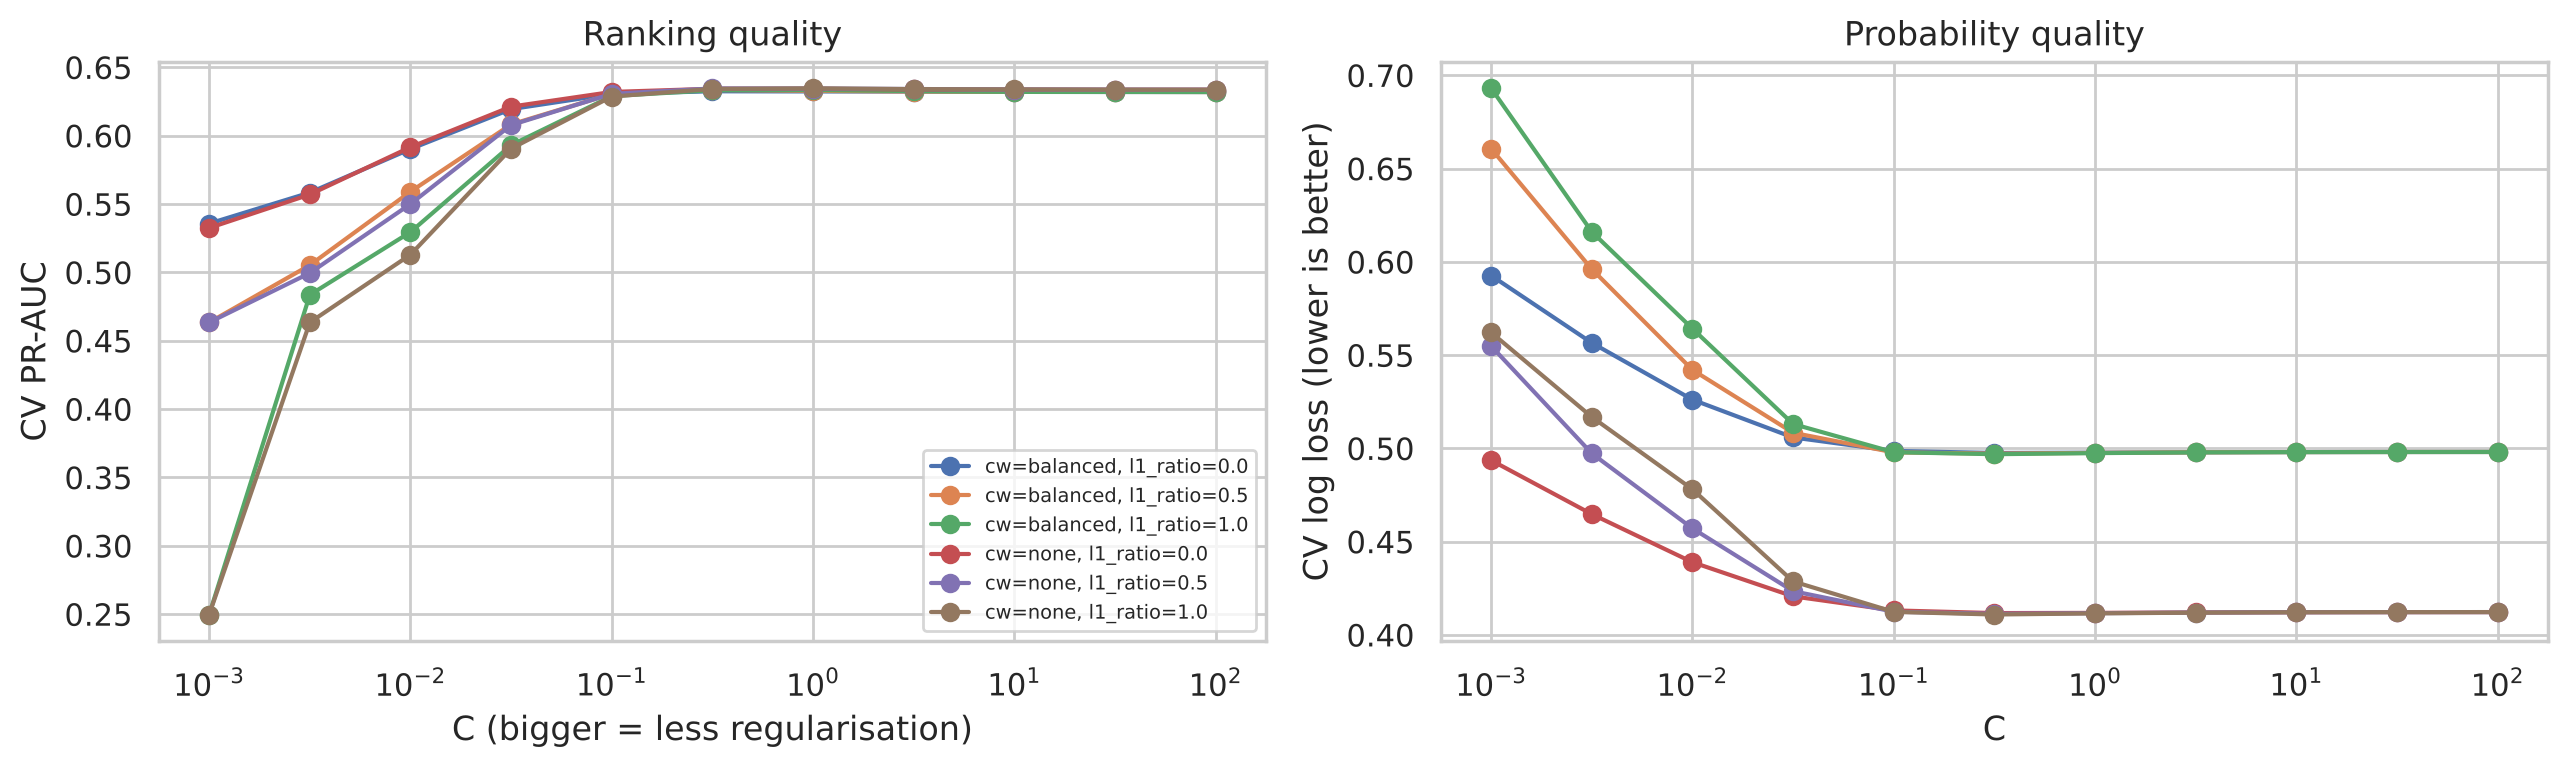

In [3]:
cv = pd.read_csv("results/cv_results.csv")
display(cv.head(8).round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (cw, l1), g in cv.groupby(["class_weight", "l1_ratio"]):
    g = g.sort_values("C")
    axes[0].semilogx(g.C, g.cv_pr_auc, marker="o", label=f"cw={cw}, l1_ratio={l1}")
    axes[1].semilogx(g.C, -g.cv_neg_log_loss, marker="o", label=f"cw={cw}, l1_ratio={l1}")
axes[0].set(xlabel="C (bigger = less regularisation)", ylabel="CV PR-AUC", title="Ranking quality")
axes[1].set(xlabel="C", ylabel="CV log loss (lower is better)", title="Probability quality")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Reading this:**
- Very small `C` (strong regularisation) underfits; above `C≈0.1` the curve is flat, so the model is not overfitting. With ~25 features and 4,000 rows, logistic regression is a low-variance model.
- L1, L2 and elastic net score almost the same. L1 wins by a hair and has a bonus: it sets weak features to exactly zero, giving a simpler model.
- **`class_weight="balanced"` gives the same PR-AUC but much worse log loss.** Reweighting doesn't change how customers are *ranked*, it shifts every probability upward. We handle imbalance by **moving the threshold** instead, which keeps probabilities honest.

## Test-set results vs baselines

In [4]:
pd.read_csv("results/test_metrics.csv").set_index("model")

,roc_auc,pr_auc,precision,recall,f1,flag_rate,threshold,log_loss,brier
model,,,,,,,,,
majority (nobody churns),0.5000,0.2491,0.0000,0.0000,0.0000,0.0000,0.50,NaN,NaN
rule: month-to-month churns,0.7004,0.3671,0.3919,0.8262,0.5316,0.5252,0.50,NaN,NaN
logreg default,0.8372,0.6294,0.6695,0.4501,0.5383,0.1675,0.50,0.4134,0.1340
"logreg tuned, class_weight=balanced",0.8369,0.6270,0.5020,0.7293,0.5947,0.3620,0.50,0.4877,0.1626
logreg tuned (final),0.8369,0.6293,0.6723,0.4558,0.5433,0.1689,0.50,0.4135,0.1341
logreg tuned (final) @ best-F1 threshold,0.8369,0.6293,0.5101,0.7208,0.5974,0.3520,0.26,0.4135,0.1341
logreg tuned (final) @ max-profit threshold,0.8369,0.6293,0.5260,0.6923,0.5978,0.3279,0.29,0.4135,0.1341


- The **month-to-month rule** catches 83% of churners but flags half of all customers (precision 0.39).
- Logistic regression lifts ROC-AUC from 0.70 to **0.84** and PR-AUC from 0.37 to **0.63** (random = 0.25).
- At the default 0.5 threshold it misses more than half the churners (recall 0.46). Lowering the threshold to the validation-chosen **0.29** raises recall to **0.69** at precision 0.53.
- Tuning barely beat the default logistic regression: honest result. The gain comes from the threshold and from checking the model properly, not from hyperparameters.

In [5]:
print(subprocess.run([sys.executable, "src/evaluate.py"], capture_output=True, text=True).stdout)

Calibration
                               model  mean_predicted  actual_rate    ece
                     logreg default          0.2393       0.2491 0.0223
logreg tuned, class_weight=balanced          0.3986       0.2491 0.1495
               logreg tuned (final)          0.2393       0.2491 0.0187 

Profit
 {'profit_at_threshold': 13349.999999999993, 'best_profit': 14450.0, 'profit_offer_everyone': -17800.0} 

Top coefficients
                        feature   coef  odds_ratio
             Contract_Two year -2.334       0.097
             Contract_One year -1.335       0.263
                        tenure -1.153       0.316
   InternetService_Fiber optic  1.083       2.952
PaymentMethod_Electronic check  0.730       2.074
               TechSupport_Yes -0.647       0.524
                  TotalCharges  0.566       1.761
            InternetService_No -0.457       0.633
            OnlineSecurity_Yes -0.415       0.661
             SeniorCitizen_Yes  0.245       1.278
          Paperl

## ROC and precision-recall curves

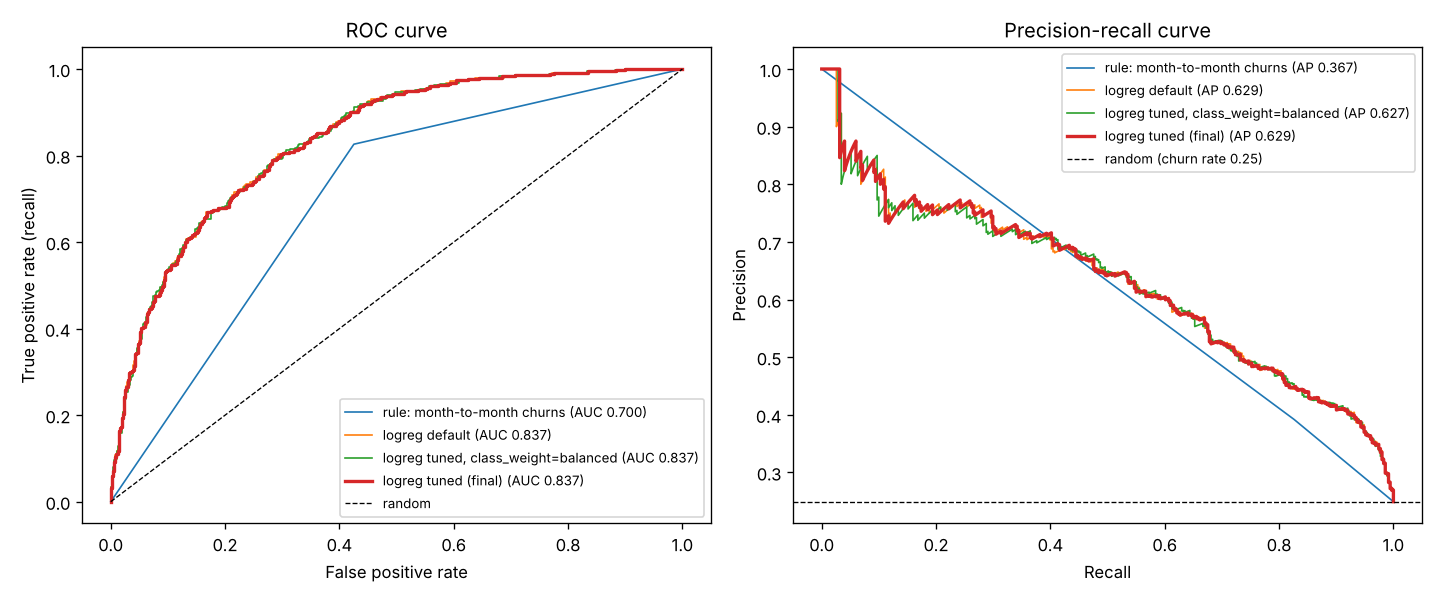

In [6]:
display(Image("results/roc_pr_curves.png"))

With 25% positives, the PR curve is the more telling one: it shows the precision you pay for each extra bit of recall.

## Calibration: can we trust the probabilities?

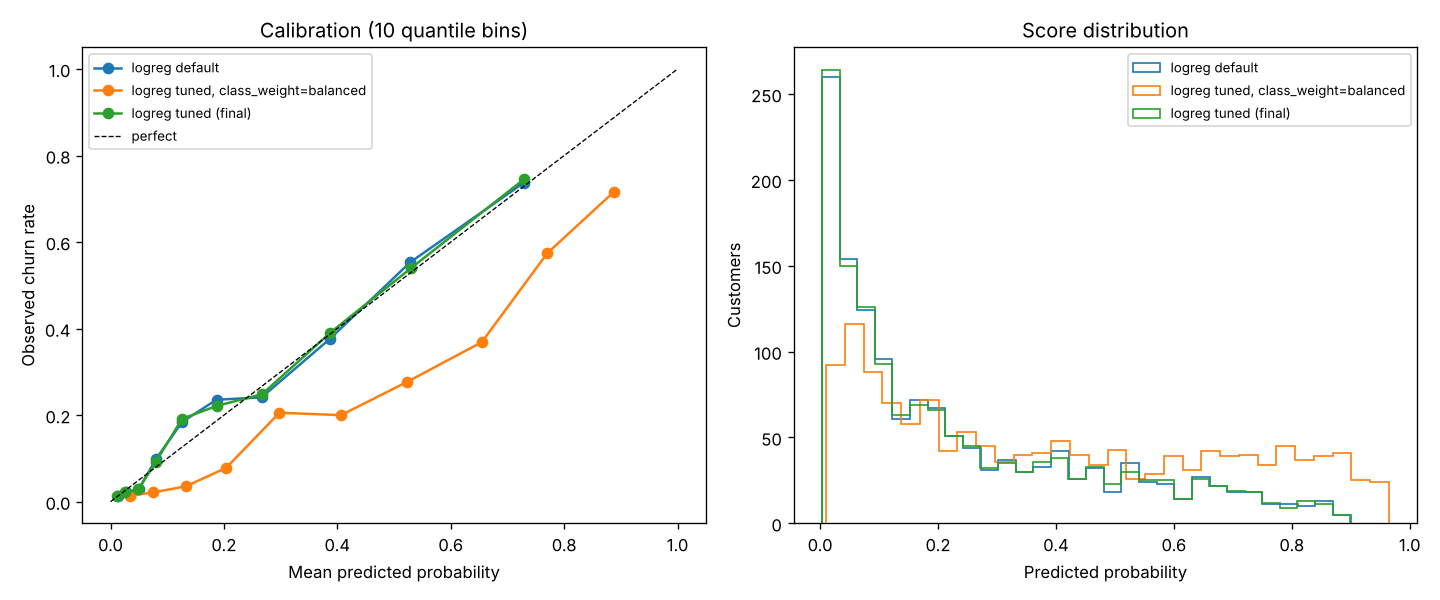

In [7]:
display(Image("results/calibration.png"))

The final model sits on the diagonal (expected calibration error ≈ 0.02): customers scored 40% churn about 40% of the time. That matters because the retention team uses the probability itself (expected loss = probability × customer value). The `balanced` model overstates risk across the board, which is why we didn't ship it.

## Choosing the threshold with business costs

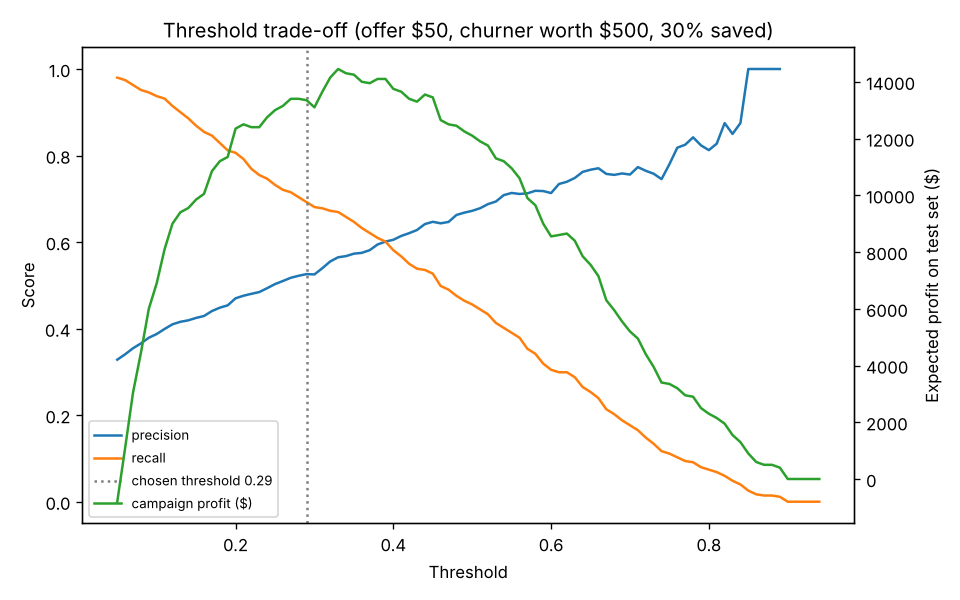

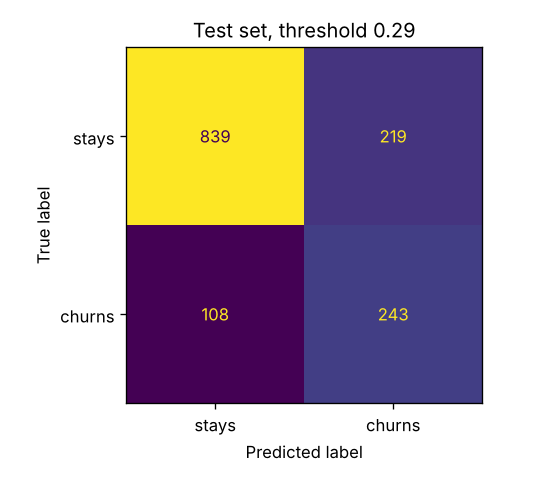

In [8]:
display(Image("results/threshold_tradeoff.png")); display(Image("results/confusion_matrix.png"))

Assumptions (edit them in `train.py`): a retention offer costs **$50**, a churner is worth **$500**, and the offer saves **30%** of churners who get it. Break-even is a churn probability of 50 / (0.3 × 500) ≈ 0.33. The validation set picked **0.29**, close to the theory.

On the test set that campaign earns roughly **+$13k**, versus **−$18k** for sending the offer to everyone.

## Lift: how concentrated are churners at the top?

,decile,customers,churners,mean_score,churn_rate,lift,cumulative_recall
0,1,141,105,0.729,0.745,2.989,0.299
1,2,141,76,0.529,0.539,2.164,0.516
2,3,141,55,0.387,0.390,1.566,0.672
3,4,141,35,0.267,0.248,0.996,0.772
4,5,141,31,0.187,0.220,0.883,0.860
5,6,140,27,0.126,0.193,0.774,0.937
6,7,141,13,0.080,0.092,0.370,0.974
7,8,141,4,0.049,0.028,0.114,0.986
8,9,141,3,0.026,0.021,0.085,0.994
9,10,141,2,0.012,0.014,0.057,1.000


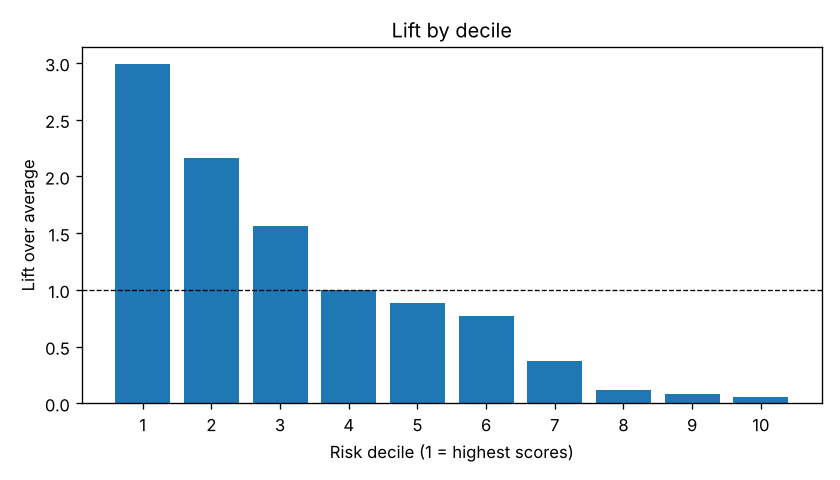

In [9]:
display(pd.read_csv("results/lift_by_decile.csv")); display(Image("results/lift_by_decile.png"))

The top 10% of scores have a ~75% churn rate (**3× lift**), and the top 30% contain two thirds of all churners. If the budget only covers 10% of customers, call these first.

## What drives churn? Coefficients as odds ratios

,feature,coef,odds_ratio
0,Contract_Two year,-2.3344,0.0969
1,Contract_One year,-1.3353,0.2631
2,tenure,-1.1528,0.3158
3,InternetService_Fiber optic,1.0826,2.9522
4,PaymentMethod_Electronic check,0.7297,2.0744
5,TechSupport_Yes,-0.6470,0.5236
6,TotalCharges,0.5657,1.7606
7,InternetService_No,-0.4565,0.6335
8,OnlineSecurity_Yes,-0.4146,0.6606
9,SeniorCitizen_Yes,0.2453,1.2780


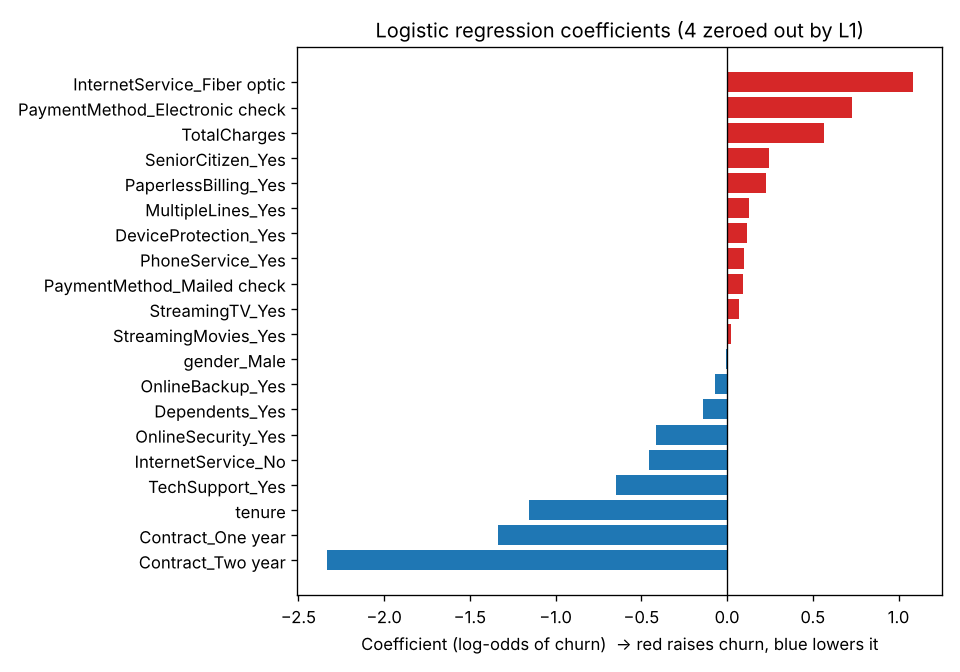

In [10]:
coef = pd.read_csv("results/coefficients.csv"); display(coef.head(15)); display(Image("results/coefficients.png"))

How to read it (numbers are log-scaled and standardised, categories compare with a reference level):
- **Two-year contract**: odds ratio ≈ 0.10, i.e. ~90% lower odds of churning than month-to-month, all else equal.
- **Fibre optic**: ≈ 3× the odds vs DSL. **Electronic cheque**: ≈ 2× vs bank transfer.
- **Tech support / online security** cut the odds by roughly 35–50%: a concrete retention lever.
- **Tenure** is strongly protective. `TotalCharges` comes out *positive* only because it overlaps with tenure (see notebook 01); read tenure and charges together, not one by one.
- L1 set four features to exactly zero (Partner, MonthlyCharges, num_addons, credit-card payment) and shrank **gender** to almost nothing (odds ratio 0.99). MonthlyCharges dropping out is again overlap: fibre and add-on columns already explain the price.

These are associations, not causes: giving everyone tech support won't necessarily cut churn by half. An A/B test would tell.

## Does it work for every group?

In [11]:
pd.read_csv("results/segment_metrics.csv")

,segment,customers,churn_rate,roc_auc,recall,precision
0,gender=Female,705,0.247,0.837,0.684,0.520
1,gender=Male,704,0.251,0.836,0.701,0.532
2,SeniorCitizen=No,1192,0.236,0.837,0.690,0.517
3,SeniorCitizen=Yes,217,0.323,0.830,0.700,0.563
4,Contract=Month-to-month,740,0.392,0.764,0.810,0.526
5,Contract=One year,326,0.135,0.773,0.182,0.615
6,Contract=Two year,343,0.050,0.823,0.000,0.000
7,InternetService=DSL,507,0.174,0.816,0.591,0.423
8,InternetService=Fiber optic,615,0.372,0.817,0.786,0.610
9,InternetService=No,287,0.118,0.803,0.324,0.250


ROC-AUC is similar across gender and senior status, so there is no obvious fairness gap. Recall is very low for two-year customers, simply because few of them reach the threshold; if those customers matter, give that segment its own threshold or model.

**Next:** `03_deploy_and_monitor.ipynb`.